In [1]:
import os
os.chdir("D:/tmp_workplace/dynamic_structure/260816/sample")
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from mlxtend.evaluate import permutation_test

In [3]:
data = []
locs = []

with open("28S_rRNA_merge_RICseq_KR_5.matrix","r")as f:
    for line in f:
        sub = line.strip().split()
        left = int(sub[0])
        right = int(sub[1])
        tmp = float(sub[2])
        if tmp > 0:
            data.append(tmp)
            locs.append((left,right))

N = len(data)

sample_size = int(N * 0.06)

In [4]:
values = np.array(data)
weights = values

In [8]:
SEED = 42
np.random.seed(SEED)

all_samples = []
for i in range(1000):
    sampled_indices = np.random.choice(
        N, 
        size=sample_size, 
        replace=False,
        p=weights/weights.sum()
    )
    #print(sampled_indices)
    sampled_locs = [locs[i] for i in sampled_indices]
    all_samples.append(sampled_locs)

In [7]:
def load_pairs(file):
    pairs = []
    with open(file,"r")as f:
        for line in f:
            if "chrom1" in line:
                continue
            sub = line.strip().split()
            left = int(sub[1])
            right = int(sub[4])
            if left < right:
                pairs.append((left,right))
    return pairs

refs = load_pairs("28S_rRNA_c.bedpe")

In [9]:
sample_coverages = []
for sample in all_samples:
    n = 0
    matrix = np.zeros((1100,1100))
    for locs in sample:
        left = int(locs[0]/5)
        right = int(locs[1]/5)
        matrix[left,right] = 1
    for pair in refs:
        l = int(pair[0]/5)
        r = int(pair[1]/5)
        if matrix[l,r] == 1:
            n += 1
    sample_coverages.append(n)

In [10]:
print(np.mean(sample_coverages),np.median(sample_coverages))

850.591 851.0


In [ ]:
p_value = permutation_test(
    [1252],           
    sample_coverages,            
    method='approximate',
    num_rounds=10000,
    func=lambda x, y: np.median(x) - np.median(y),  
    seed=13
)

print(f"p-value: {p_value:.4f}")

p-value: 0.0013


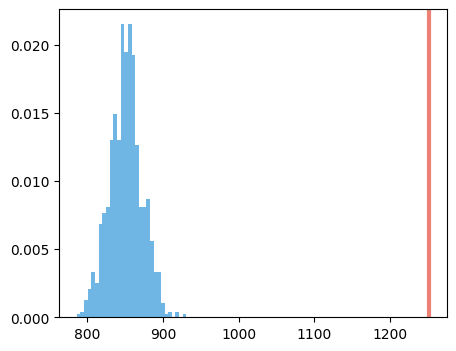

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))

#ax.hist(pdcov_target_list, bins=100, density=True, alpha=0.7, color='#e74c3c')
ax.axvline(x=1252, color='#e74c3c', linewidth=3, alpha=0.7)
ax.hist(sample_coverages, bins=30, density=True, alpha=0.7, color='#3498db')

plt.savefig("random_pick.pdf",format="pdf")
plt.show()